In [1]:
import pandas as pd

water_cleaned = pd.read_csv(
    "merged_complete_datasets/berlin_water_quality_cleaned.csv",
    parse_dates=["date"]
)

In [5]:
water_cleaned.head()

,date,bathing_water_quality,coliform_bacteria,cyanobacteria_chl_a,e_coli,intestinal_enterococci,water_visibility_depth,water_temperature,lake,water_temperature_raw,...,e_coli_numeric,intestinal_enterococci_raw,intestinal_enterococci_qualifier,intestinal_enterococci_numeric,cyanobacteria_chl_a_raw,cyanobacteria_chl_a_qualifier,cyanobacteria_chl_a_numeric,water_visibility_depth_raw,water_visibility_depth_qualifier,water_visibility_depth_numeric
0,2025-04-29,Suitable for bathing,< 300,"0,0000","< 15,00","< 15,00","> 1,00","16,00",Flughafensee,"16,00",...,15.0,"< 15,00",<,15.0,"0,0000",NaN,0.0,"> 1,00",>,1.0
1,2025-05-15,Suitable for bathing,< 300,"0,20","< 15,00","< 15,00","> 1,00","17,50",Flughafensee,"17,50",...,15.0,"< 15,00",<,15.0,"0,20",NaN,0.2,"> 1,00",>,1.0
2,2025-05-26,Suitable for bathing,360,"0,10","30,00","15,00",NaN,"17,70",Flughafensee,"17,70",...,30.0,"15,00",NaN,15.0,"0,10",NaN,0.1,NaN,NaN,NaN
3,2025-06-11,NaN,null 910,"null 0,30","null 30,00","null 15,00","> 1,00","null 17,80",Flughafensee,"null 17,80",...,30.0,"null 15,00",NaN,15.0,"null 0,30",NaN,0.3,"> 1,00",>,1.0
4,2025-07-10,NaN,< 300,"null 0,0000","null 15,00","null 15,00","> 1,00","null 21,50",Flughafensee,"null 21,50",...,15.0,"null 15,00",NaN,15.0,"null 0,0000",NaN,0.0,"> 1,00",>,1.0


In [6]:
# Restore the bathing-water classification as a category
water_cleaned["bathing_water_quality"] = (
    water_cleaned["bathing_water_quality"].astype("category")
)

# Ensure dates are datetime
water_cleaned["date"] = pd.to_datetime(water_cleaned["date"])

In [7]:
# Check dataset dimensions
print("Dataset shape:", water_cleaned.shape)

# Inspect column names and data types
print("\nDataset information:")
water_cleaned.info()

# Preview the first records
display(water_cleaned.head())

Dataset shape: (118, 28)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 28 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   date                              118 non-null    datetime64[us]
 1   bathing_water_quality             82 non-null     category      
 2   coliform_bacteria                 117 non-null    str           
 3   cyanobacteria_chl_a               54 non-null     str           
 4   e_coli                            118 non-null    str           
 5   intestinal_enterococci            118 non-null    str           
 6   water_visibility_depth            109 non-null    str           
 7   water_temperature                 116 non-null    str           
 8   lake                              118 non-null    str           
 9   water_temperature_raw             116 non-null    str           
 10  water_temperat

,date,bathing_water_quality,coliform_bacteria,cyanobacteria_chl_a,e_coli,intestinal_enterococci,water_visibility_depth,water_temperature,lake,water_temperature_raw,...,e_coli_numeric,intestinal_enterococci_raw,intestinal_enterococci_qualifier,intestinal_enterococci_numeric,cyanobacteria_chl_a_raw,cyanobacteria_chl_a_qualifier,cyanobacteria_chl_a_numeric,water_visibility_depth_raw,water_visibility_depth_qualifier,water_visibility_depth_numeric
0,2025-04-29,Suitable for bathing,< 300,"0,0000","< 15,00","< 15,00","> 1,00","16,00",Flughafensee,"16,00",...,15.0,"< 15,00",<,15.0,"0,0000",NaN,0.0,"> 1,00",>,1.0
1,2025-05-15,Suitable for bathing,< 300,"0,20","< 15,00","< 15,00","> 1,00","17,50",Flughafensee,"17,50",...,15.0,"< 15,00",<,15.0,"0,20",NaN,0.2,"> 1,00",>,1.0
2,2025-05-26,Suitable for bathing,360,"0,10","30,00","15,00",NaN,"17,70",Flughafensee,"17,70",...,30.0,"15,00",NaN,15.0,"0,10",NaN,0.1,NaN,NaN,NaN
3,2025-06-11,NaN,null 910,"null 0,30","null 30,00","null 15,00","> 1,00","null 17,80",Flughafensee,"null 17,80",...,30.0,"null 15,00",NaN,15.0,"null 0,30",NaN,0.3,"> 1,00",>,1.0
4,2025-07-10,NaN,< 300,"null 0,0000","null 15,00","null 15,00","> 1,00","null 21,50",Flughafensee,"null 21,50",...,15.0,"null 15,00",NaN,15.0,"null 0,0000",NaN,0.0,"> 1,00",>,1.0


In [8]:
# Count samples by lake and year
water_cleaned["year"] = water_cleaned["date"].dt.year

sampling_overview = (
    water_cleaned
    .groupby(["lake", "year"], observed=True)
    .size()
    .unstack(fill_value=0)
)

print("Sampling records by lake and year:")
display(sampling_overview)

# Calculate total samples per lake
print("\nTotal samples per lake:")
display(water_cleaned["lake"].value_counts())

Sampling records by lake and year:


year,2025,2026
lake,,
Flughafensee,9,10
Müggelsee,10,10
Orankesee,10,10
Tegeler See,10,10
Wannsee,9,10
Weißensee,10,10



Total samples per lake:


lake
Müggelsee       20
Orankesee       20
Tegeler See     20
Weißensee       20
Flughafensee    19
Wannsee         19
Name: count, dtype: int64

In [9]:
# Select the main measurement columns
measurement_columns = [
    "water_temperature_numeric",
    "coliform_bacteria_numeric",
    "cyanobacteria_chl_a_numeric",
    "e_coli_numeric",
    "intestinal_enterococci_numeric",
    "water_visibility_depth_numeric"
]

# Calculate missing values and percentages
missing_summary = pd.DataFrame({
    "missing_count": water_cleaned[measurement_columns].isna().sum(),
    "missing_percentage": (
        water_cleaned[measurement_columns].isna().mean() * 100
    ).round(1)
})

print(missing_summary.sort_values(
    "missing_percentage",
    ascending=False
))

                                missing_count  missing_percentage
cyanobacteria_chl_a_numeric                64                54.2
water_visibility_depth_numeric              9                 7.6
water_temperature_numeric                   3                 2.5
coliform_bacteria_numeric                   1                 0.8
e_coli_numeric                              0                 0.0
intestinal_enterococci_numeric              0                 0.0


In [10]:
# Summarise water temperature by lake and year
water_temp_summary = (
    water_cleaned
    .groupby(["lake", "year"], observed=True)
    ["water_temperature_numeric"]
    .agg(
        sample_count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(2)
    .reset_index()
)

display(water_temp_summary)

,lake,year,sample_count,mean,median,std,minimum,maximum
0,Flughafensee,2025,9,19.63,20.60,2.41,16.0,23.1
1,Flughafensee,2026,10,21.42,21.10,2.27,17.0,25.3
2,Müggelsee,2025,10,19.66,20.25,2.94,14.5,23.4
3,Müggelsee,2026,10,20.20,20.15,2.14,15.2,22.8
4,Orankesee,2025,10,20.37,21.20,2.22,17.4,23.3
5,Orankesee,2026,9,21.20,21.20,2.13,17.3,25.2
6,Tegeler See,2025,10,19.47,19.20,2.55,15.7,23.0
7,Tegeler See,2026,9,19.44,19.90,3.35,13.1,24.0
8,Wannsee,2025,8,19.91,20.50,2.06,16.6,22.2
9,Wannsee,2026,10,19.61,20.40,3.39,12.3,23.3


In [11]:
# Compare mean water temperature between years
temperature_comparison = (
    water_temp_summary
    .pivot(
        index="lake",
        columns="year",
        values="mean"
    )
)

temperature_comparison["change_celsius"] = (
    temperature_comparison[2026] - temperature_comparison[2025]
)

temperature_comparison["change_percentage"] = (
    temperature_comparison["change_celsius"]
    / temperature_comparison[2025] * 100
)

display(temperature_comparison.round(2))

year,2025,2026,change_celsius,change_percentage
lake,,,,
Flughafensee,19.63,21.42,1.79,9.12
Müggelsee,19.66,20.20,0.54,2.75
Orankesee,20.37,21.20,0.83,4.07
Tegeler See,19.47,19.44,-0.03,-0.15
Wannsee,19.91,19.61,-0.30,-1.51
Weißensee,20.46,21.79,1.33,6.50


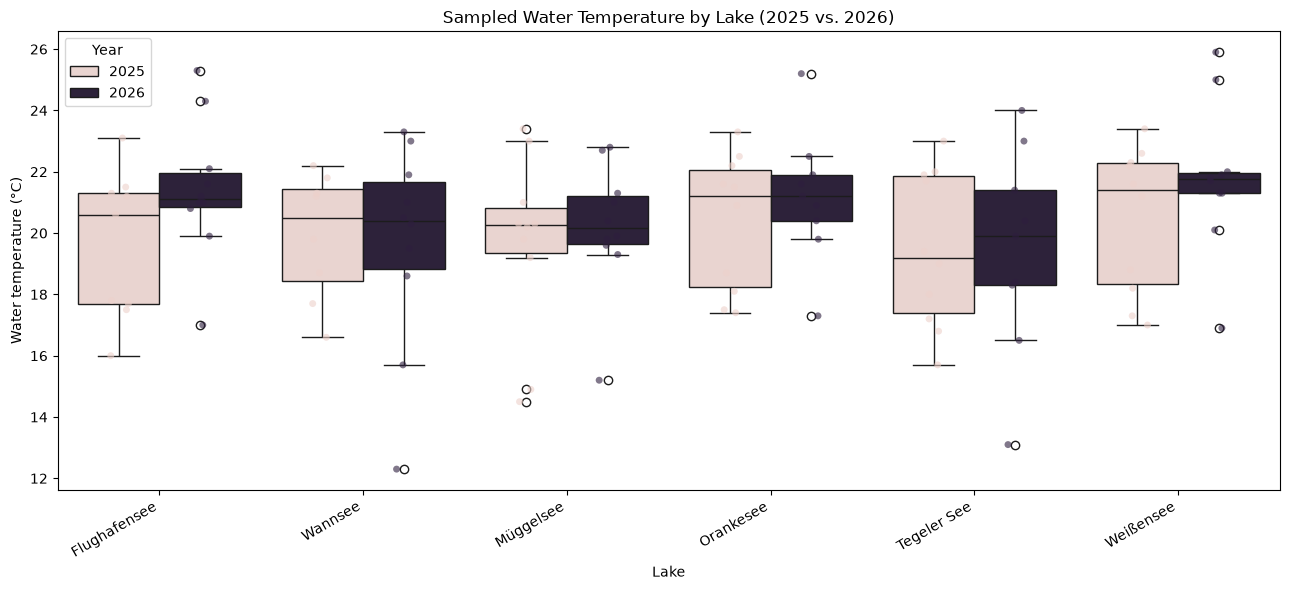

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 6))

# Compare sampled water temperatures by lake and year
sns.boxplot(
    data=water_cleaned,
    x="lake",
    y="water_temperature_numeric",
    hue="year"
)

# Show individual sampling observations
sns.stripplot(
    data=water_cleaned,
    x="lake",
    y="water_temperature_numeric",
    hue="year",
    dodge=True,
    alpha=0.6,
    jitter=True,
    legend=False
)

plt.title("Sampled Water Temperature by Lake (2025 vs. 2026)")
plt.xlabel("Lake")
plt.ylabel("Water temperature (°C)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

- General Warming Trend in 2026: In most of the observed lakes—specifically Flughafensee, Müggelsee, Orankesee, and Weißensee—the median water temperature (indicated by the horizontal line inside the boxes) was noticeably higher in 2026 compared to 2025.
- Wannsee maintained a very similar median temperature across both years, but its 2026 data shows significantly wider overall variability, pushing into both lower extremes (down to ~12°C) and higher extremes.
- Tegeler See is the only lake where the median temperature appeared roughly unchanged or slightly lower in 2026, though its middle 50% distribution (the interquartile range) expanded significantly in 2026 compared to the tightly clustered core of 2025.
- Most Stable Temperature Profile: Weißensee features the most compact inner quartile range in 2026, indicating that while it warmed up, its core summer/sampled temperatures were highly consistent around 21.5°C to 22°C (despite a few extreme outlier data points).
- Outliers Across Data Sets: Almost every lake contains individual outlier measurements (represented by the open circles outside the whiskers) in both years, showing extreme weather events or isolated anomaly readings dipping as low as ~12°C or peaking near 26°C.

This is only out of 8 to 10 observations per lake

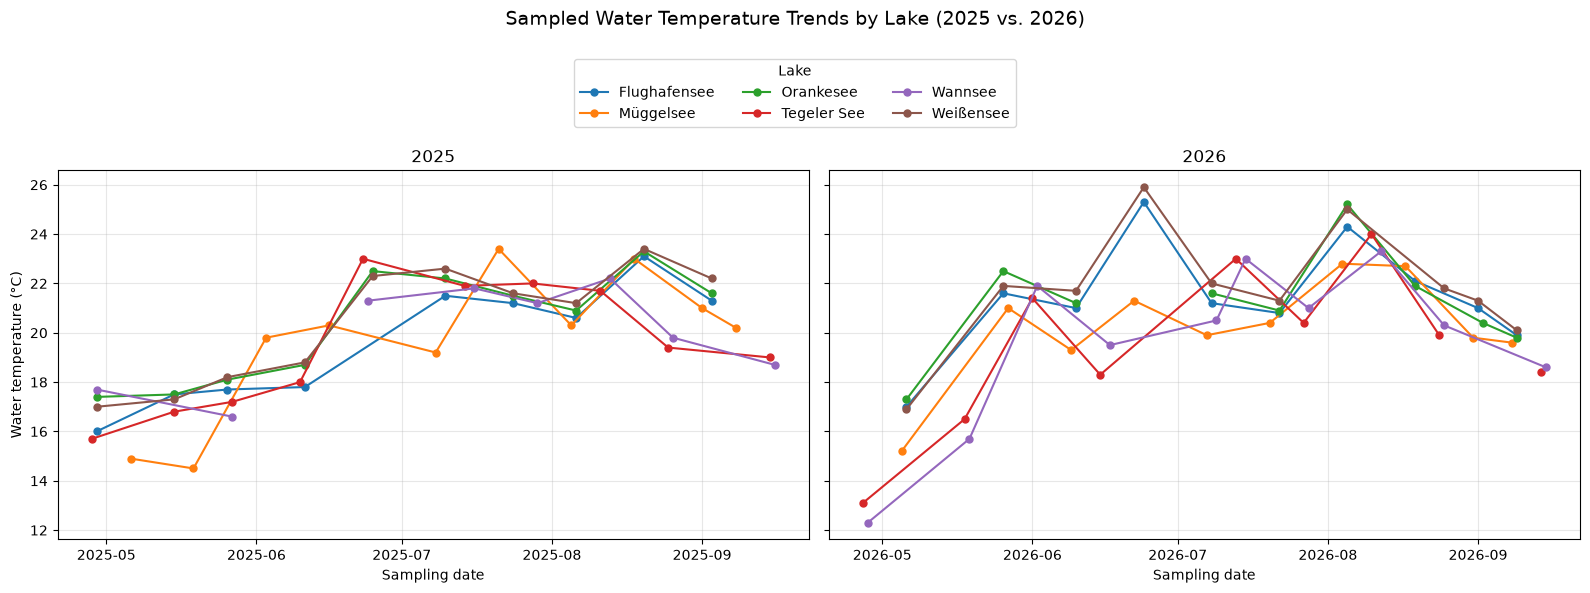

In [13]:
# Define the lakes and consistent colours across both panels
lake_order = sorted(water_cleaned["lake"].dropna().unique())
palette = sns.color_palette("tab10", n_colors=len(lake_order))

# Create two side-by-side panels with a shared temperature scale
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, year in zip(axes, [2025, 2026]):

    # Filter observations for the selected year
    year_data = water_cleaned[water_cleaned["year"] == year]

    # Plot one line per lake in chronological order
    for lake, color in zip(lake_order, palette):
        lake_data = (
            year_data[year_data["lake"] == lake]
            .sort_values("date")
        )

        ax.plot(
            lake_data["date"],
            lake_data["water_temperature_numeric"],
            marker="o",
            markersize=5,
            linewidth=1.5,
            label=lake,
            color=color
        )

    ax.set_title(str(year))
    ax.set_xlabel("Sampling date")
    ax.grid(alpha=0.3)

# Add shared labels and title
axes[0].set_ylabel("Water temperature (°C)")

fig.suptitle(
    "Sampled Water Temperature Trends by Lake (2025 vs. 2026)",
    fontsize=14
)

# Display one shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Lake",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=3
)

plt.tight_layout(rect=[0, 0, 1, 0.83])
plt.show()

- Higher observed peaks in 2026: several lakes, particularly Weißensee and Flughafensee, reached sampled temperatures close to 26°C in late June 2026. In 2025, the highest observed values were approximately 23–23.5°C and occurred later in the summer.
- Different timing of observed temperature peaks: the 2026 measurements showed an early temperature peak in late June, followed by another increase in August. In contrast, the 2025 observations showed a more gradual increase, with the highest sampled temperatures occurring around mid-to-late August.
- Lower temperatures at the beginning of the 2026 sampling period: the May 2026 observations included particularly low temperatures of approximately 12–13°C in Wannsee and Tegeler See. The May 2025 measurements were generally higher, mostly around 14.5–16°C.
- Similar cooling towards September: by mid-to-late September, sampled temperatures across the lakes were generally between 18°C and 20°C in both years, suggesting a similar late-season cooling pattern.

In [14]:
# Count exact and qualified E. coli measurements by lake and year
ecoli_summary = (
    water_cleaned
    .groupby(["lake", "year"], observed=True)
    .agg(
        total_samples=("e_coli_numeric", "count"),
        exact_measurements=(
            "e_coli_qualifier",
            lambda x: x.isna().sum()
        ),
        qualified_measurements=(
            "e_coli_qualifier",
            lambda x: x.notna().sum()
        )
    )
    .reset_index()
)

display(ecoli_summary)

,lake,year,total_samples,exact_measurements,qualified_measurements
0,Flughafensee,2025,9,7,2
1,Flughafensee,2026,10,5,5
2,Müggelsee,2025,10,1,9
3,Müggelsee,2026,10,1,9
4,Orankesee,2025,10,4,6
5,Orankesee,2026,10,7,3
6,Tegeler See,2025,10,3,7
7,Tegeler See,2026,10,4,6
8,Wannsee,2025,9,2,7
9,Wannsee,2026,10,0,10


Note for the analysis

- Exact measurement: a measurement with a defined exact number on the dataset (for example 15, 300 etc.)
- Qualified measurement: a measurement which was found smaller/bigger than a certain value (for example < 15 or > 300)

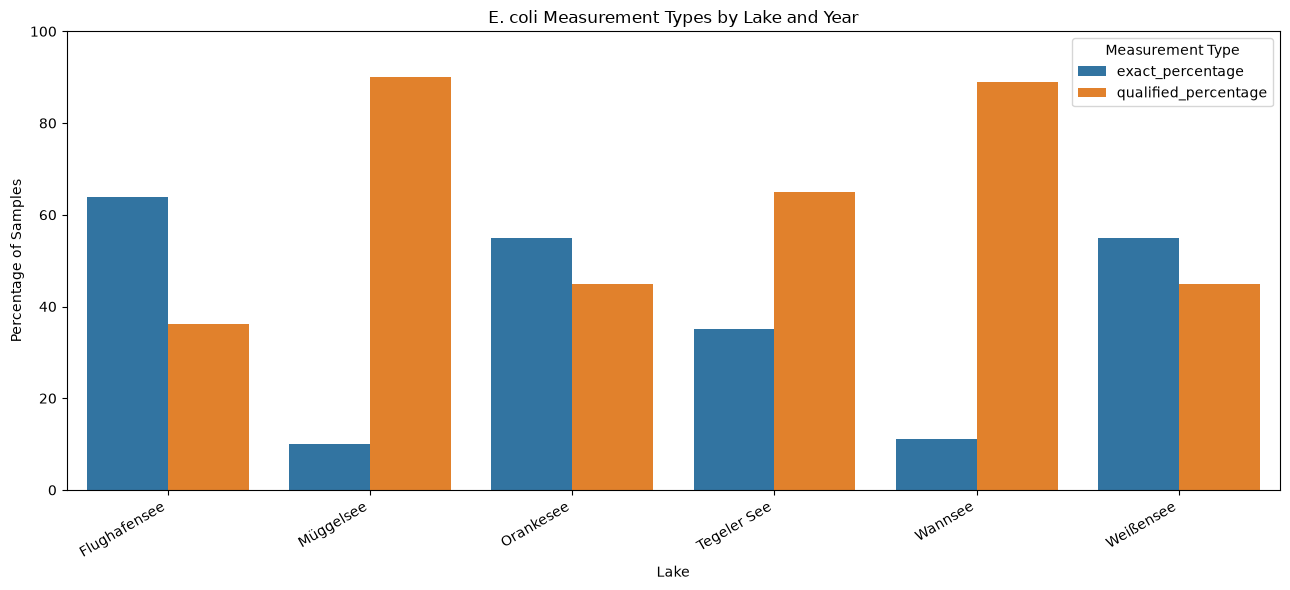

In [15]:
# Calculate percentages of exact and qualified measurements
ecoli_percentages = ecoli_summary.copy()

ecoli_percentages["exact_percentage"] = (
    ecoli_percentages["exact_measurements"]
    / ecoli_percentages["total_samples"] * 100
)

ecoli_percentages["qualified_percentage"] = (
    ecoli_percentages["qualified_measurements"]
    / ecoli_percentages["total_samples"] * 100
)

# Reshape the data for plotting
ecoli_plot = ecoli_percentages.melt(
    id_vars=["lake", "year"],
    value_vars=[
        "exact_percentage",
        "qualified_percentage"
    ],
    var_name="measurement_type",
    value_name="percentage"
)

# Create the stacked bar chart
plt.figure(figsize=(13, 6))

sns.barplot(
    data=ecoli_plot,
    x="lake",
    y="percentage",
    hue="measurement_type",
    errorbar=None
)

plt.title("E. coli Measurement Types by Lake and Year")
plt.xlabel("Lake")
plt.ylabel("Percentage of Samples")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.legend(title="Measurement Type")
plt.tight_layout()
plt.show()

- High proportion of qualified results: Müggelsee and Wannsee had the highest proportions, with approximately 90% of results below the quantification limit in both years combined. Tegeler See also had a relatively high proportion.
- Higher availability of exact measurements: Flughafensee and Orankesee had comparatively more exact results. Flughafensee had the highest overall proportion of exact measurements.
- More balanced distribution: Weißensee had a relatively even split between exact and qualified results.
- Year-specific differences: Wannsee had no exact measurements in 2026, while Orankesee had more exact measurements in 2026 than in 2025.

In [16]:
# Keep only exact E. coli measurements
ecoli_exact = water_cleaned[
    water_cleaned["e_coli_qualifier"].isna()
].copy()

# Calculate descriptive statistics by lake and year
ecoli_stats = (
    ecoli_exact
    .groupby(["lake", "year"], observed=True)
    ["e_coli_numeric"]
    .agg(
        sample_count="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .round(2)
    .reset_index()
)

display(ecoli_stats)

,lake,year,sample_count,mean,median,minimum,maximum
0,Flughafensee,2025,7,39.71,30.0,15.0,143.0
1,Flughafensee,2026,5,172.20,30.0,15.0,740.0
2,Müggelsee,2025,1,15.00,15.0,15.0,15.0
3,Müggelsee,2026,1,15.00,15.0,15.0,15.0
4,Orankesee,2025,4,37.75,37.5,30.0,46.0
5,Orankesee,2026,7,82.43,61.0,15.0,251.0
6,Tegeler See,2025,3,15.00,15.0,15.0,15.0
7,Tegeler See,2026,4,19.00,15.0,0.0,46.0
8,Wannsee,2025,2,15.00,15.0,15.0,15.0
9,Weißensee,2025,6,25.00,22.5,15.0,45.0


In [17]:
# Inspect exact E. coli records with a numeric value of zero
zero_ecoli = water_cleaned[
    (water_cleaned["e_coli_numeric"] == 0) &
    (water_cleaned["e_coli_qualifier"].isna())
]

display(
    zero_ecoli[
        ["lake", "date", "e_coli", "e_coli_raw", "e_coli_numeric"]
    ]
)

,lake,date,e_coli,e_coli_raw,e_coli_numeric
96,Tegeler See,2026-09-07,"0,0000","0,0000",0.0


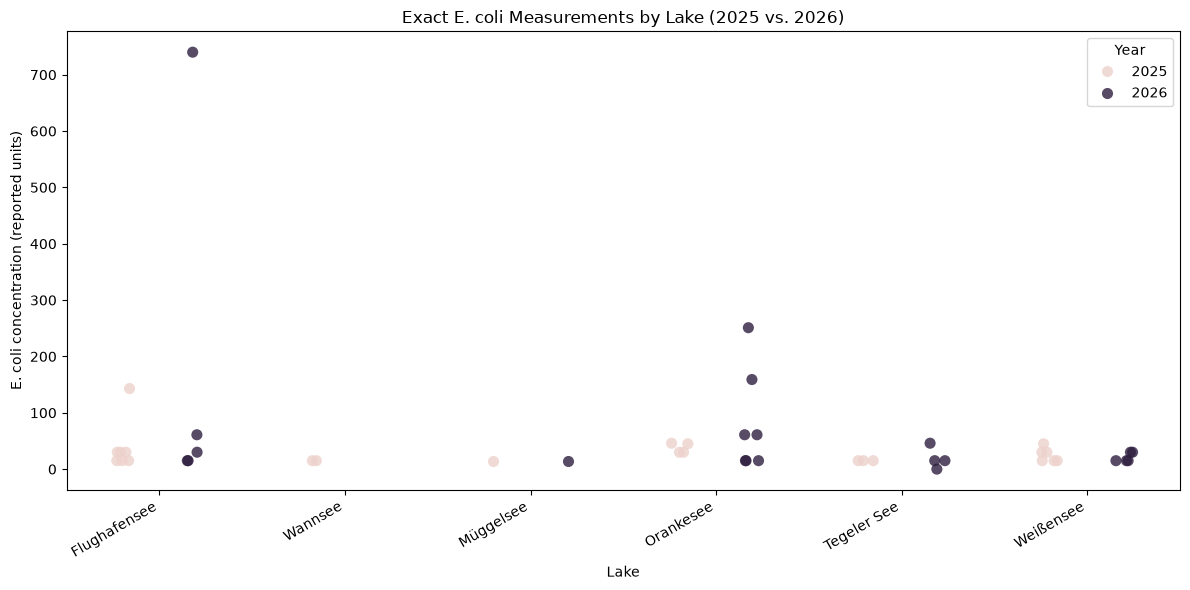

In [18]:
# Visualize exact E. coli measurements by lake and year
plt.figure(figsize=(12, 6))

sns.stripplot(
    data=ecoli_exact,
    x="lake",
    y="e_coli_numeric",
    hue="year",
    dodge=True,
    jitter=True,
    alpha=0.8,
    size=8
)

plt.title("Exact E. coli Measurements by Lake (2025 vs. 2026)")
plt.xlabel("Lake")
plt.ylabel("E. coli concentration (reported units)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

- Flughafensee — a pronounced 2026 spike: The highest exact measurement was 740 in 2026, compared with a maximum of 143 in 2025. The 2026 mean is strongly influenced by this one high result, while the median remained 30 in both years.
- Orankesee — higher and more dispersed exact readings in 2026: Its maximum increased from 46 in 2025 to 251 in 2026. The median also increased from 37.5 to 61. This suggests higher readings in the exact-measurement subset, although the sample sizes are small (4 and 7).
- Other lakes — mostly low exact readings: Exact results for Müggelsee, Tegeler See, Wannsee and Weißensee were all below 50. However, there are important limitations:
- Müggelsee had only one exact result per year.
- Wannsee had no exact results in 2026.
- Many other samples were reported as <15, meaning below the quantification limit rather than an exact value of 15.

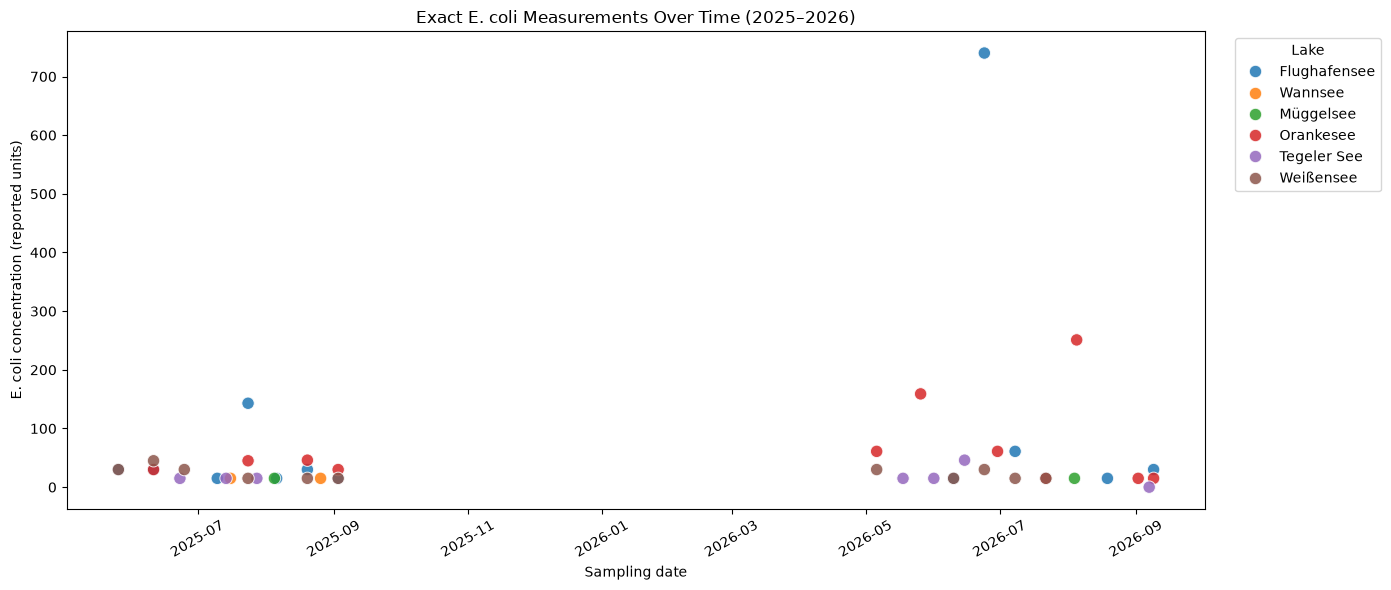

In [19]:
# Plot exact E. coli measurements over time
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=ecoli_exact,
    x="date",
    y="e_coli_numeric",
    hue="lake",
    s=80,
    alpha=0.85
)

plt.title("Exact E. coli Measurements Over Time (2025–2026)")
plt.xlabel("Sampling date")
plt.ylabel("E. coli concentration (reported units)")
plt.xticks(rotation=30)
plt.legend(title="Lake", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Higher E. coli readings were observed during the 2026 bathing season, particularly at Flughafensee and Orankesee. Flughafensee recorded the highest exact measurement, reaching 740 in late June 2026, while Orankesee recorded a maximum of 251. In comparison, most exact measurements in 2025 remained below 50, apart from a reading of 143 at Flughafensee. The available observations are concentrated in the warmer recreational months, with a substantial sampling gap between September 2025 and May 2026. Consequently, the dataset does not support conclusions about winter water quality or continuous seasonal trends.

In [22]:
import numpy as np

# Identify exact and qualified E. coli measurements
water_cleaned["e_coli_result_type"] = np.where(
    water_cleaned["e_coli_qualifier"].isna(),
    "Exact",
    "Below quantification limit"
)

# Check the number of records in each category
display(
    water_cleaned["e_coli_result_type"]
    .value_counts()
)

e_coli_result_type
Below quantification limit    73
Exact                         45
Name: count, dtype: int64

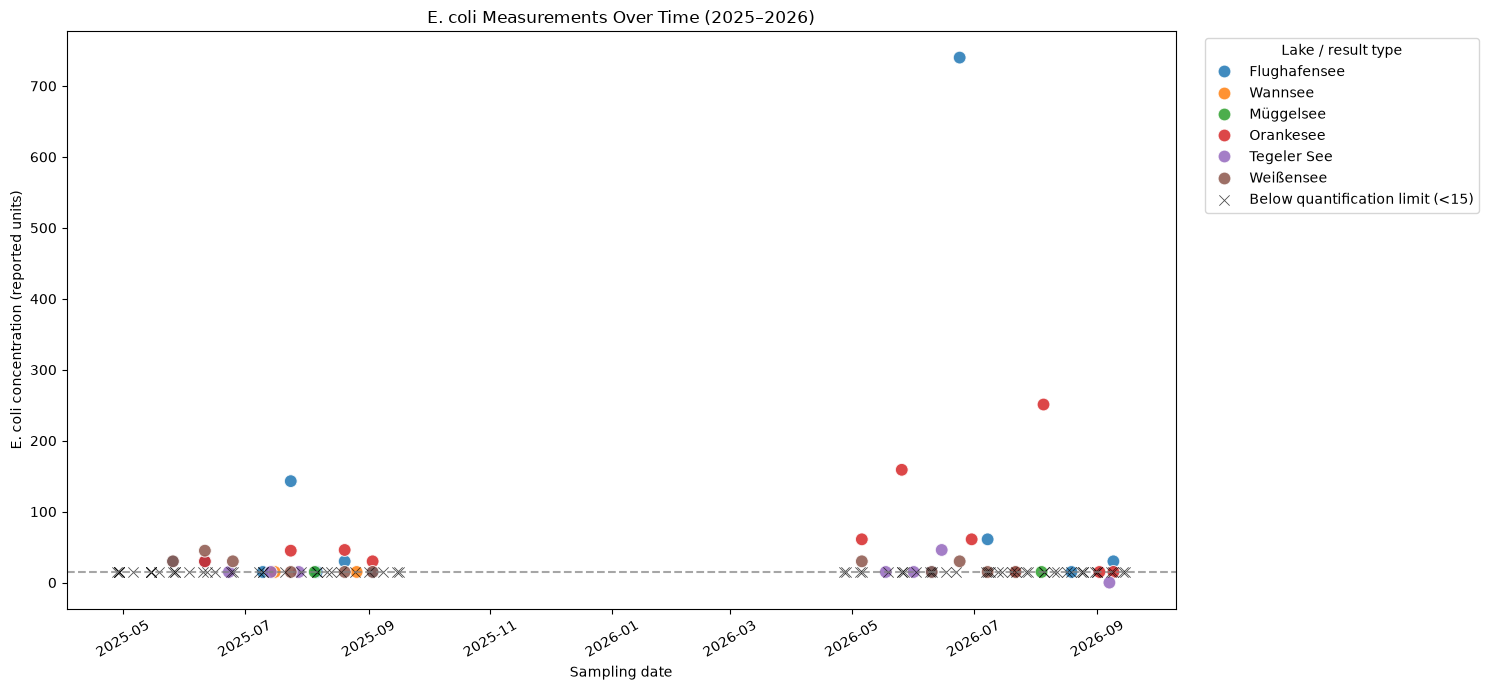

In [ ]:
#including also qualified measurements

# Separate exact and qualified measurements
ecoli_qualified = water_cleaned[
    water_cleaned["e_coli_result_type"] == "Below quantification limit"
].copy()

# Create the time-series chart
plt.figure(figsize=(15, 7))

# Plot exact measurements
sns.scatterplot(
    data=ecoli_exact,
    x="date",
    y="e_coli_numeric",
    hue="lake",
    s=85,
    alpha=0.85
)

# Add qualified measurements at the reporting limit
sns.scatterplot(
    data=ecoli_qualified,
    x="date",
    y=[15] * len(ecoli_qualified),
    marker="x",
    color="black",
    s=55,
    alpha=0.7,
    label="Below quantification limit (<15)"
)

# Show the reporting limit
plt.axhline(
    y=15,
    linestyle="--",
    color="grey",
    alpha=0.7
)

plt.title("E. coli Measurements Over Time (2025–2026)")
plt.xlabel("Sampling date")
plt.ylabel("E. coli concentration (reported units)")
plt.xticks(rotation=30)
plt.legend(title="Lake / result type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Most E. coli results were reported below the quantification limit. Of the 118 samples collected across six Berlin lakes, 73 (61.9%) were reported as below 15 units, while 45 contained exact numerical measurements. The combined time-series visualisation highlights a large number of results below the reporting limit, alongside substantially higher individual readings at Flughafensee and Orankesee during 2026. This distinction is important because the qualified results cannot be treated as exact concentrations, and the observed high readings should not be interpreted as confirmed regulatory exceedances without checking the applicable bathing-water standards.

In [24]:
# Calculate exact and qualified results by lake and year
ecoli_result_summary = (
    water_cleaned
    .groupby(["lake", "year", "e_coli_result_type"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Calculate the percentage below the quantification limit
ecoli_result_summary["below_limit_pct"] = (
    ecoli_result_summary["Below quantification limit"]
    / (
        ecoli_result_summary["Below quantification limit"]
        + ecoli_result_summary["Exact"]
    ) * 100
).round(1)

display(ecoli_result_summary)

e_coli_result_type,lake,year,Below quantification limit,Exact,below_limit_pct
0,Flughafensee,2025,2,7,22.2
1,Flughafensee,2026,5,5,50.0
2,Müggelsee,2025,9,1,90.0
3,Müggelsee,2026,9,1,90.0
4,Orankesee,2025,6,4,60.0
5,Orankesee,2026,3,7,30.0
6,Tegeler See,2025,7,3,70.0
7,Tegeler See,2026,6,4,60.0
8,Wannsee,2025,7,2,77.8
9,Wannsee,2026,10,0,100.0


- Orankesee: The share below the quantification limit fell from 60% to 30%, consistent with the higher number of exact results in 2026.
- Flughafensee: The share below the limit increased from 22.2% to 50%, despite the extreme 740 result. This illustrates why a single high result and the overall distribution must be considered separately.
- Müggelsee: 90% of results were below the limit in both years, but there was only one exact result each year.
- Wannsee: All 10 results in 2026 were below the limit. This does not mean all concentrations were zero; their exact values were not quantified.

In [25]:
# Keep records with exact E. coli results and available water temperature
ecoli_temp = water_cleaned[
    water_cleaned["e_coli_qualifier"].isna() &
    water_cleaned["water_temperature_numeric"].notna()
].copy()

# Check how many paired observations are available
print("Number of paired observations:", len(ecoli_temp))

# Inspect the relevant columns
display(
    ecoli_temp[
        [
            "lake",
            "year",
            "date",
            "water_temperature_numeric",
            "e_coli_numeric"
        ]
    ].head()
)

Number of paired observations: 43


,lake,year,date,water_temperature_numeric,e_coli_numeric
2,Flughafensee,2025,2025-05-26,17.7,30.0
3,Flughafensee,2025,2025-06-11,17.8,30.0
4,Flughafensee,2025,2025-07-10,21.5,15.0
5,Flughafensee,2025,2025-07-24,21.2,143.0
6,Flughafensee,2025,2025-08-06,20.6,15.0


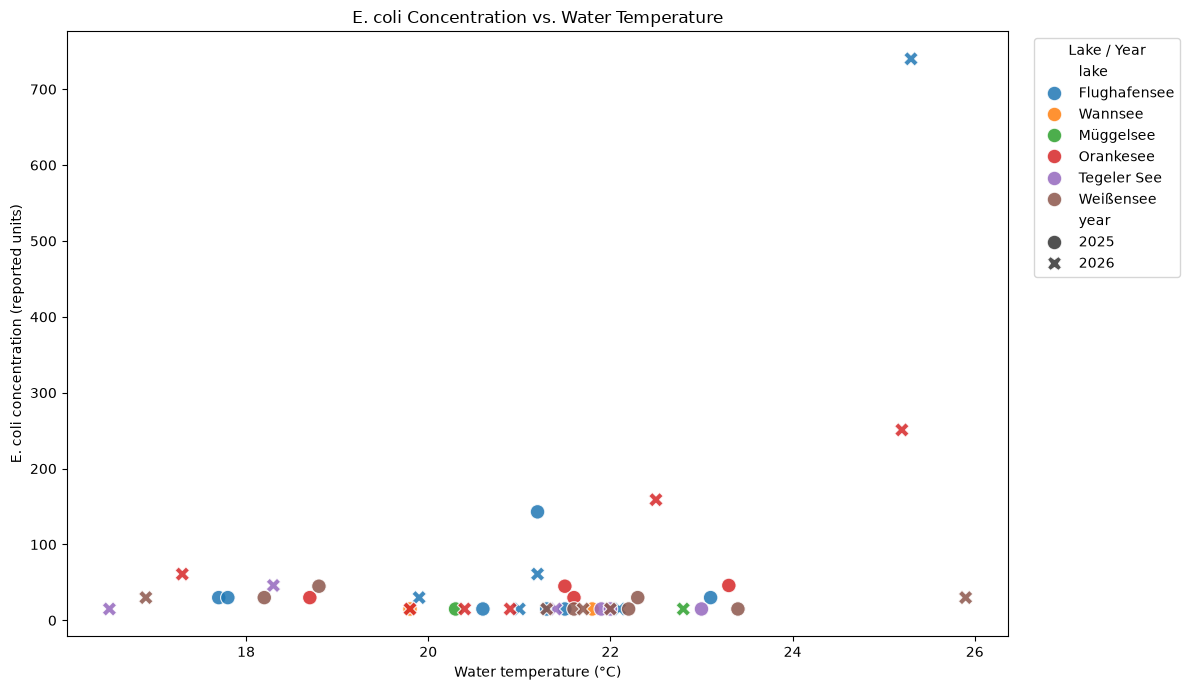

In [26]:
# Compare exact E. coli measurements with water temperature
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=ecoli_temp,
    x="water_temperature_numeric",
    y="e_coli_numeric",
    hue="lake",
    style="year",
    s=110,
    alpha=0.85
)

plt.title("E. coli Concentration vs. Water Temperature")
plt.xlabel("Water temperature (°C)")
plt.ylabel("E. coli concentration (reported units)")
plt.legend(
    title="Lake / Year",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

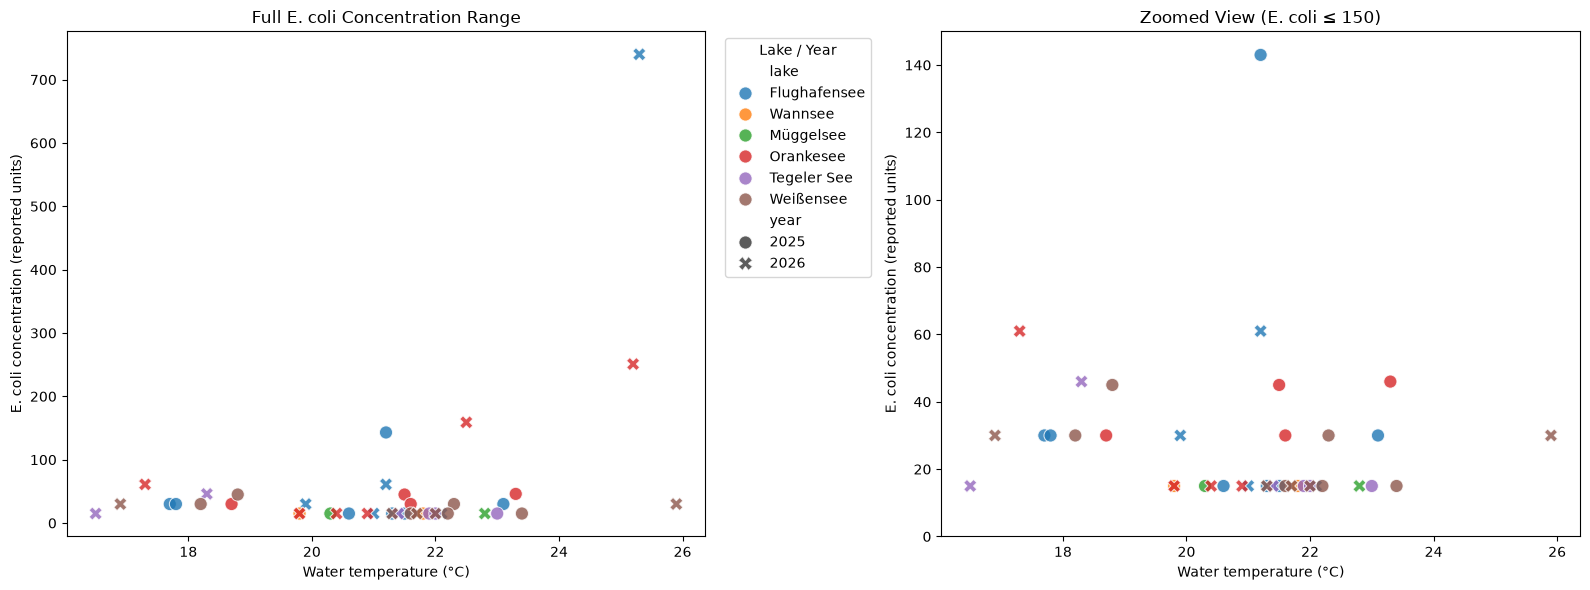

In [ ]:
# Create full-scale and zoomed-in scatterplots for better visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Full-scale view
sns.scatterplot(
    data=ecoli_temp,
    x="water_temperature_numeric",
    y="e_coli_numeric",
    hue="lake",
    style="year",
    s=90,
    alpha=0.8,
    ax=axes[0]
)

axes[0].set_title("Full E. coli Concentration Range")
axes[0].set_xlabel("Water temperature (°C)")
axes[0].set_ylabel("E. coli concentration (reported units)")

# Zoomed-in view: concentrations up to 150
ecoli_temp_zoom = ecoli_temp[
    ecoli_temp["e_coli_numeric"] <= 150
]

sns.scatterplot(
    data=ecoli_temp_zoom,
    x="water_temperature_numeric",
    y="e_coli_numeric",
    hue="lake",
    style="year",
    s=90,
    alpha=0.8,
    ax=axes[1],
    legend=False
)

axes[1].set_title("Zoomed View (E. coli ≤ 150)")
axes[1].set_xlabel("Water temperature (°C)")
axes[1].set_ylabel("E. coli concentration (reported units)")
axes[1].set_ylim(0, 150)

# Keep one legend for both charts
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
    handles,
    labels,
    title="Lake / Year",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Higher E. coli readings coincided with warmer water temperatures in some sampling events during 2026. The most extreme observations, including the 740-unit result at Flughafensee and the 251-unit result at Orankesee, occurred at water temperatures above 25°C. However, many samples collected at similarly warm temperatures still showed relatively low exact concentrations. This suggests that warmer water alone does not explain the observed variation in E. coli levels. The relationship remains exploratory because of the limited number of exact measurements and uneven sampling across lakes and dates.

In [28]:
from scipy.stats import spearmanr

# Calculate overall correlation
overall_corr, overall_p = spearmanr(
    ecoli_temp["water_temperature_numeric"],
    ecoli_temp["e_coli_numeric"]
)

# Calculate correlations separately by year
yearly_corr = (
    ecoli_temp
    .groupby("year")
    .apply(
        lambda group: spearmanr(
            group["water_temperature_numeric"],
            group["e_coli_numeric"]
        ),
        include_groups=False
    )
)

# Display results
print(f"Overall Spearman correlation: {overall_corr:.3f}")
print(f"Overall p-value: {overall_p:.4f}")

for year, result in yearly_corr.items():
    print(f"{year}: Spearman correlation = {result.statistic:.3f}, p-value = {result.pvalue:.4f}")

Overall Spearman correlation: -0.006
Overall p-value: 0.9679
2025: Spearman correlation = -0.211, p-value = 0.3345
2026: Spearman correlation = 0.191, p-value = 0.4210


No meaningful monotonic association was identified between water temperature and E. coli concentration. The combined Spearman correlation was −0.006 (p = 0.9679), indicating virtually no association in the available exact measurements. Although some of the highest E. coli readings occurred at relatively warm water temperatures in 2026, this pattern was not consistent across the full dataset. Water temperature alone therefore does not appear to explain the observed variation in E. coli concentrations.

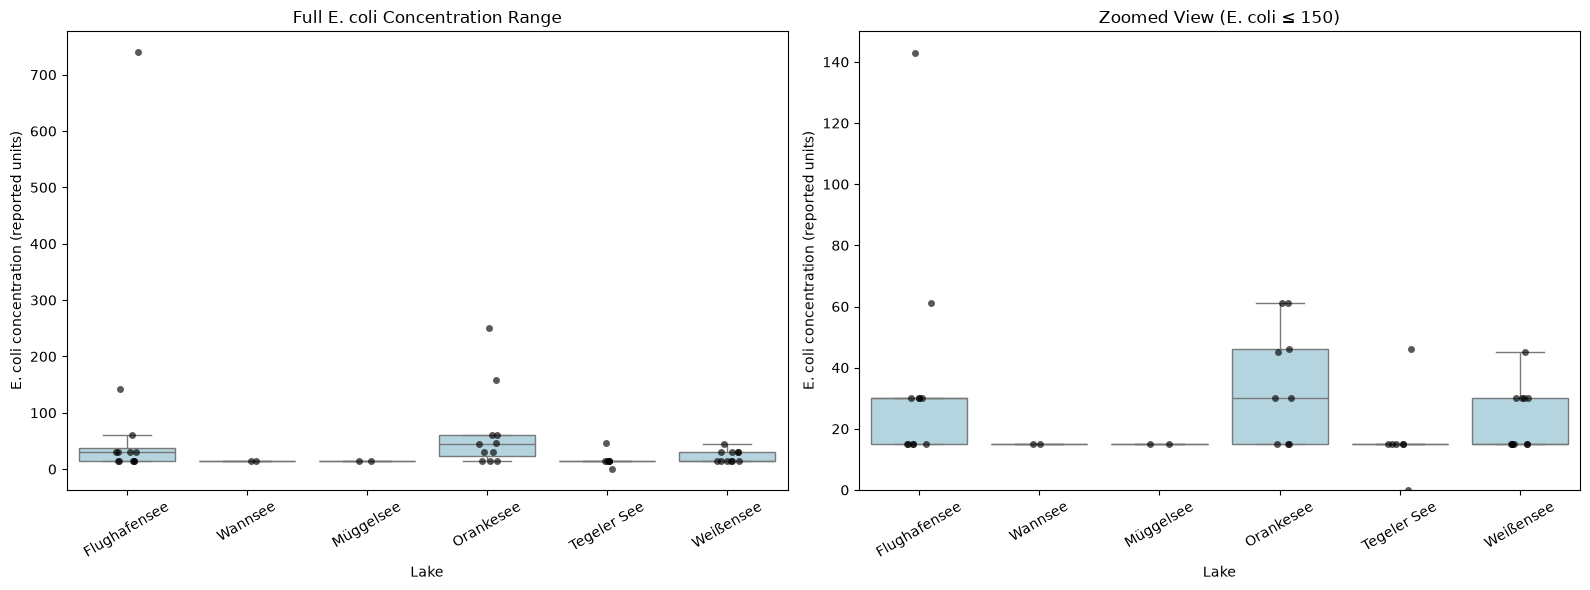

In [31]:
# Create full-scale and zoomed-in boxplots without duplicate outliers
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Full-scale view
sns.boxplot(
    data=ecoli_exact,
    x="lake",
    y="e_coli_numeric",
    color="lightblue",
    showfliers=False,
    ax=axes[0]
)

sns.stripplot(
    data=ecoli_exact,
    x="lake",
    y="e_coli_numeric",
    color="black",
    jitter=True,
    alpha=0.65,
    size=5,
    ax=axes[0]
)

axes[0].set_title("Full E. coli Concentration Range")
axes[0].set_xlabel("Lake")
axes[0].set_ylabel("E. coli concentration (reported units)")
axes[0].tick_params(axis="x", rotation=30)

# Zoomed-in view
sns.boxplot(
    data=ecoli_exact_zoom,
    x="lake",
    y="e_coli_numeric",
    color="lightblue",
    showfliers=False,
    ax=axes[1]
)

sns.stripplot(
    data=ecoli_exact_zoom,
    x="lake",
    y="e_coli_numeric",
    color="black",
    jitter=True,
    alpha=0.65,
    size=5,
    ax=axes[1]
)

axes[1].set_title("Zoomed View (E. coli ≤ 150)")
axes[1].set_xlabel("Lake")
axes[1].set_ylabel("E. coli concentration (reported units)")
axes[1].set_ylim(0, 150)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

The boxplots show that most exact E. coli measurements were below 50 reported units across the six lakes. However, the distributions vary between lakes, and the number of exact measurements differs substantially.

Orankesee and Weißensee show a wider spread of exact measurements, while Wannsee, Müggelsee and Tegeler See have more tightly clustered observations around 15. The latter pattern should be interpreted cautiously because these lakes have relatively few exact measurements.

Flughafensee recorded the highest individual value, reaching 740 in 2026, while Orankesee reached 251. These observations stand out against the lower values recorded in the same lakes. However, the available sampling frequency does not establish whether these were isolated events or part of longer periods of elevated concentrations.

In [32]:
# Check the completeness and reporting qualifiers for intestinal enterococci
enterococci_col = "intestinal_enterococci_numeric"
enterococci_qualifier = "intestinal_enterococci_qualifier"
enterococci_raw = "intestinal_enterococci_raw"

print("Total sampling records:", len(water_cleaned))

print("\nMissing numeric results:")
print(water_cleaned[enterococci_col].isna().sum())

print("\nReporting qualifiers:")
print(water_cleaned[enterococci_qualifier].value_counts(dropna=False))

print("\nRaw result examples:")
print(water_cleaned[enterococci_raw].value_counts(dropna=False).head(15))

print("\nExact vs qualified results:")
print(
    water_cleaned[enterococci_qualifier]
    .isna()
    .map({True: "Exact", False: "Qualified"})
    .value_counts()
)

Total sampling records: 118

Missing numeric results:
0

Reporting qualifiers:
intestinal_enterococci_qualifier
<      95
NaN    23
Name: count, dtype: int64

Raw result examples:
intestinal_enterococci_raw
< 15,00       95
15,00         14
null 15,00     4
30,00          2
null 109       1
109            1
0,0000         1
Name: count, dtype: int64

Exact vs qualified results:
intestinal_enterococci_qualifier
Qualified    95
Exact        23
Name: count, dtype: int64


In [33]:
# Inspect exact intestinal enterococci measurements
enterococci_exact = water_cleaned[
    water_cleaned["intestinal_enterococci_qualifier"].isna()
].copy()

display(
    enterococci_exact[
        [
            "lake",
            "date",
            "year",
            "intestinal_enterococci",
            "intestinal_enterococci_raw",
            "intestinal_enterococci_numeric",
            "intestinal_enterococci_qualifier",
            "water_temperature_numeric"
        ]
    ].sort_values(
        "intestinal_enterococci_numeric",
        ascending=False
    )
)

,lake,date,year,intestinal_enterococci,intestinal_enterococci_raw,intestinal_enterococci_numeric,intestinal_enterococci_qualifier,water_temperature_numeric
5,Flughafensee,2025-07-24,2025,null 109,null 109,109.0,NaN,21.2
12,Flughafensee,2026-06-24,2026,109,109,109.0,NaN,25.3
74,Orankesee,2026-08-05,2026,"30,00","30,00",30.0,NaN,25.2
112,Weißensee,2026-07-08,2026,"30,00","30,00",30.0,NaN,22.0
3,Flughafensee,2025-06-11,2025,"null 15,00","null 15,00",15.0,NaN,17.8
4,Flughafensee,2025-07-10,2025,"null 15,00","null 15,00",15.0,NaN,21.5
2,Flughafensee,2025-05-26,2025,"15,00","15,00",15.0,NaN,17.7
10,Flughafensee,2026-05-26,2026,"15,00","15,00",15.0,NaN,21.6
8,Flughafensee,2025-09-03,2025,"15,00","15,00",15.0,NaN,21.3
70,Orankesee,2026-06-10,2026,"15,00","15,00",15.0,NaN,21.2


In [34]:
# Label exact and below-quantification-limit results
water_cleaned["enterococci_result_type"] = np.where(
    water_cleaned["intestinal_enterococci_qualifier"].isna(),
    "Exact",
    "Below quantification limit"
)

# Count each result type by lake and year
enterococci_counts = (
    water_cleaned
    .groupby(["lake", "year", "enterococci_result_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Calculate the percentage of results below the quantification limit
enterococci_counts["below_limit_pct"] = (
    enterococci_counts["Below quantification limit"]
    / (
        enterococci_counts["Below quantification limit"]
        + enterococci_counts["Exact"]
    )
    * 100
).round(1)

display(enterococci_counts)

enterococci_result_type,lake,year,Below quantification limit,Exact,below_limit_pct
0,Flughafensee,2025,4,5,44.4
1,Flughafensee,2026,7,3,70.0
2,Müggelsee,2025,10,0,100.0
3,Müggelsee,2026,10,0,100.0
4,Orankesee,2025,9,1,90.0
5,Orankesee,2026,5,5,50.0
6,Tegeler See,2025,10,0,100.0
7,Tegeler See,2026,8,2,80.0
8,Wannsee,2025,9,0,100.0
9,Wannsee,2026,10,0,100.0


In [35]:
# Keep exact intestinal enterococci measurements only
enterococci_exact = water_cleaned[
    water_cleaned["intestinal_enterococci_qualifier"].isna()
].copy()

# Summarise exact measurements by lake and year
enterococci_summary = (
    enterococci_exact
    .groupby(["lake", "year"])["intestinal_enterococci_numeric"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .round(2)
    .reset_index()
)

display(enterococci_summary)

,lake,year,n,mean,median,minimum,maximum
0,Flughafensee,2025,5,33.80,15.0,15.0,109.0
1,Flughafensee,2026,3,46.33,15.0,15.0,109.0
2,Orankesee,2025,1,15.00,15.0,15.0,15.0
3,Orankesee,2026,5,18.00,15.0,15.0,30.0
4,Tegeler See,2026,2,7.50,7.5,0.0,15.0
5,Weißensee,2025,2,15.00,15.0,15.0,15.0
6,Weißensee,2026,5,18.00,15.0,15.0,30.0


Intestinal enterococci results were below the quantification limit of 15 CFU/100 ml in 80.5% of the 118 sampling records. Among exact measurements, the highest concentrations were observed at Flughafensee, reaching 109 CFU/100 ml in both 2025 and 2026. Orankesee and Weißensee recorded maximum exact values of 30 CFU/100 ml in 2026. Median exact concentrations remained at 15 CFU/100 ml for the lakes with comparable observations. However, the limited number of exact results and the high proportion of below-limit measurements restrict comparisons between lakes and years.

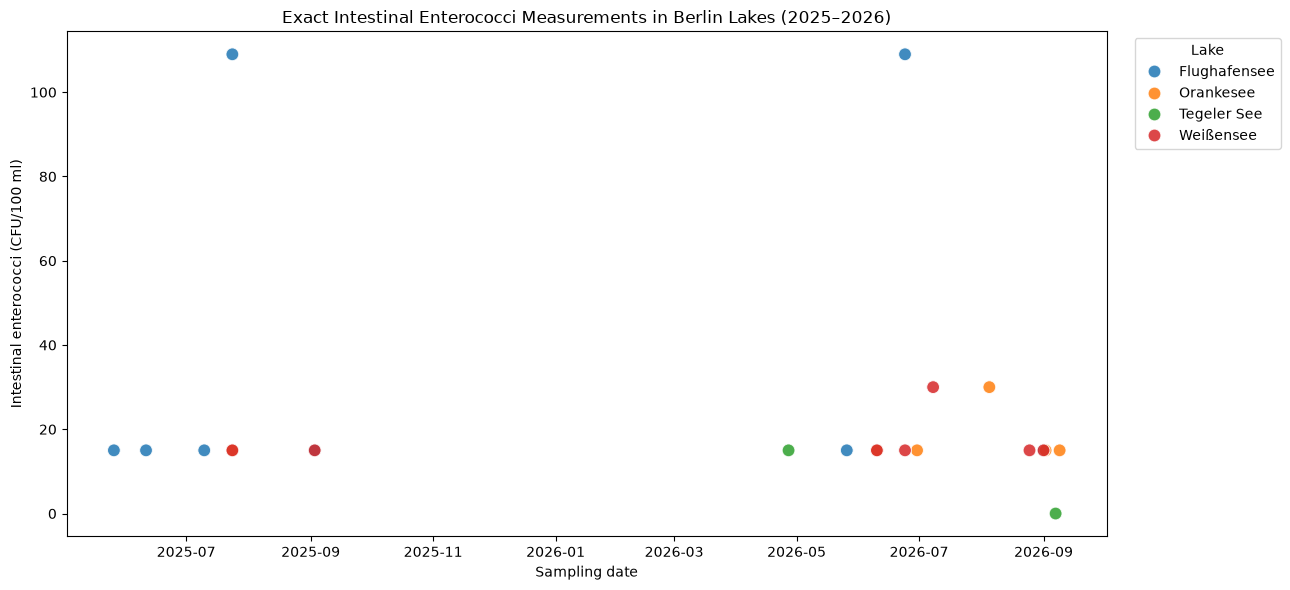

In [36]:
# Plot exact intestinal enterococci measurements over time
plt.figure(figsize=(13, 6))

sns.scatterplot(
    data=enterococci_exact,
    x="date",
    y="intestinal_enterococci_numeric",
    hue="lake",
    s=85,
    alpha=0.85
)

plt.title("Exact Intestinal Enterococci Measurements in Berlin Lakes (2025–2026)")
plt.xlabel("Sampling date")
plt.ylabel("Intestinal enterococci (CFU/100 ml)")
plt.legend(title="Lake", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Intestinal enterococci concentrations were below the quantification limit of 15 CFU/100 ml in 80.5% of the 118 sampling records. Among exact measurements, Flughafensee recorded the highest values, reaching 109 CFU/100 ml on 24 July 2025 and 24 June 2026.

Most other exact measurements were 15 CFU/100 ml. Orankesee and Weißensee recorded values of 30 CFU/100 ml in 2026, while Tegeler See had one reported value of 0 CFU/100 ml in September 2026.

The high proportion of below-limit results and the small number of exact observations limit comparisons between lakes and years. The results describe individual sampling events rather than continuous water-quality conditions.

In [37]:
# Inspect cyanobacteria data completeness and reporting qualifiers
cyano_col = "cyanobacteria_chl_a_numeric"
cyano_qualifier = "cyanobacteria_chl_a_qualifier"
cyano_raw = "cyanobacteria_chl_a_raw"

print("Total sampling records:", len(water_cleaned))

print("\nMissing numeric results:")
print(water_cleaned[cyano_col].isna().sum())

print("\nReporting qualifiers:")
print(water_cleaned[cyano_qualifier].value_counts(dropna=False))

print("\nRaw result examples:")
print(water_cleaned[cyano_raw].value_counts(dropna=False).head(20))

Total sampling records: 118

Missing numeric results:
64

Reporting qualifiers:
cyanobacteria_chl_a_qualifier
NaN    118
Name: count, dtype: int64

Raw result examples:
cyanobacteria_chl_a_raw
NaN            64
null 0,0000    14
0,0000          9
null 1,00       3
null 1,10       3
0,20            2
0,10            2
null 0,30       2
null 14,00      2
null 0,50       2
null 10,00      1
null 7,00       1
null 7,80       1
0,30            1
0,50            1
null 0,10       1
null 1,60       1
null 13,00      1
null 0,70       1
null 1,50       1
Name: count, dtype: int64


In [38]:
# Inspect the distribution of reported cyanobacteria values
cyano_col = "cyanobacteria_chl_a_numeric"

print("Descriptive statistics:")
print(water_cleaned[cyano_col].describe())

print("\nReported values:")
print(water_cleaned[cyano_col].value_counts(dropna=True).sort_index())

# Check how many results are available for each lake and year
print("\nCompleteness by lake and year:")
cyano_completeness = (
    water_cleaned
    .groupby(["lake", "year"])[cyano_col]
    .agg(
        total_records="size",
        reported_results="count",
        missing_results=lambda x: x.isna().sum()
    )
    .reset_index()
)

cyano_completeness["reported_pct"] = (
    cyano_completeness["reported_results"]
    / cyano_completeness["total_records"] * 100
).round(1)

print(cyano_completeness.to_string(index=False))

Descriptive statistics:
count    54.000000
mean      1.640741
std       3.551217
min       0.000000
25%       0.000000
50%       0.200000
75%       1.075000
max      14.000000
Name: cyanobacteria_chl_a_numeric, dtype: float64

Reported values:
cyanobacteria_chl_a_numeric
0.0     23
0.1      3
0.2      3
0.3      3
0.5      3
0.7      1
0.8      1
1.0      3
1.1      3
1.5      1
1.6      1
1.9      1
2.1      1
4.6      1
7.0      1
7.8      1
10.0     1
13.0     1
14.0     2
Name: count, dtype: int64

Completeness by lake and year:
        lake  year  total_records  reported_results  missing_results  reported_pct
Flughafensee  2025              9                 8                1          88.9
Flughafensee  2026             10                 0               10           0.0
   Müggelsee  2025             10                10                0         100.0
   Müggelsee  2026             10                 0               10           0.0
   Orankesee  2025             10             

In [39]:
# Analyse reported cyanobacteria results from 2025 only
cyano_2025 = water_cleaned[
    (water_cleaned["year"] == 2025)
    & (water_cleaned["cyanobacteria_chl_a_numeric"].notna())
].copy()

# Summarise reported values by lake
cyano_2025_summary = (
    cyano_2025
    .groupby("lake")["cyanobacteria_chl_a_numeric"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .round(2)
    .reset_index()
)

print("2025 cyanobacteria results by lake:")
print(cyano_2025_summary.to_string(index=False))

# Inspect the highest individual readings
print("\nHighest reported readings:")
print(
    cyano_2025[
        ["lake", "date", "cyanobacteria_chl_a_raw",
         "cyanobacteria_chl_a_numeric"]
    ]
    .sort_values("cyanobacteria_chl_a_numeric", ascending=False)
    .head(15)
    .to_string(index=False)
)

2025 cyanobacteria results by lake:
        lake  n  mean  median  minimum  maximum
Flughafensee  8  0.08    0.00      0.0      0.3
   Müggelsee 10  1.85    0.60      0.0     13.0
   Orankesee  9  0.17    0.00      0.0      1.5
 Tegeler See 10  0.40    0.25      0.0      1.1
     Wannsee  9  6.01    7.00      0.0     14.0
   Weißensee  8  1.24    0.65      0.0      4.6

Highest reported readings:
       lake       date cyanobacteria_chl_a_raw  cyanobacteria_chl_a_numeric
    Wannsee 2025-08-26              null 14,00                         14.0
    Wannsee 2025-09-16              null 14,00                         14.0
  Müggelsee 2025-08-18              null 13,00                         13.0
    Wannsee 2025-07-16              null 10,00                         10.0
    Wannsee 2025-08-13               null 7,80                          7.8
    Wannsee 2025-07-29               null 7,00                          7.0
  Weißensee 2025-08-06               null 4,60                      

In the available 2025 samples, chlorophyll-a concentrations varied considerably between lakes. Wannsee recorded the highest median (7.0 µg/l) and maximum (14.0 µg/l), followed by Müggelsee, which reached 13.0 µg/l on one sampling date. Flughafensee and Orankesee showed comparatively low reported values. However, no cyanobacteria chlorophyll-a results were available for 2026, preventing a year-on-year comparison. Chlorophyll-a is also an indicator of phytoplankton biomass and should not, without further confirmation, be interpreted as a direct measure of cyanobacteria abundance or toxin risk.